## Part 2 – Feature Selection
### Exercise 4: Correlation-based selection
**Dataset:** Titanic dataset

In [2]:
# Compute correlation matrix for numerical variables
# Drop variables with high correlation (>0.85)

import seaborn as sns
import pandas as pd
import numpy as np
# Using titanic from part 1 exercise 1
from sklearn.preprocessing import LabelEncoder, OneHotEncoder

# Load Titanic dataset
titanic = sns.load_dataset('titanic')
#titanic.head()

# 1. Create FamilySize = sibsp + parch + 1
titanic['FamilySize'] = titanic['sibsp'] + titanic['parch'] + 1

# 2. Create IsAlone = 1 if FamilySize == 1 else 0
titanic['IsAlone'] = np.where(titanic['FamilySize'] == 1, 1, 0)

# 3. Convert 'sex' column into numerical format (0=female, 1=male)
titanic['sex'] = np.where(titanic['sex'] == 'male', 1, 0)

# Using titanic from part 1 exercise 1
c_matrix = titanic[['FamilySize','sibsp','survived']].corr()
coloms = c_matrix.columns

drop1 = set()
drop2 = set()
ceep1 = set()
ceep2 = set()
for i in range(len(coloms)):
    for j in range(i + 1, len(coloms)):
        col1 = coloms[i]
        col2 = coloms[j]
        vlaue = c_matrix.loc[col1, col2]
        if vlaue > 0.85:
            drop1.add(col1)
            drop2.add(col2)
        else:
            ceep1.add(col1)
            ceep2.add(col2)

c_matrix = c_matrix.drop(index=drop2, columns=drop2)
c_matrix.head() # <-- viser kunn FamilySize og survived pga. sibsp og FamiliSize har for høy corr


,FamilySize,survived
FamilySize,1.000000,0.016639
survived,0.016639,1.000000


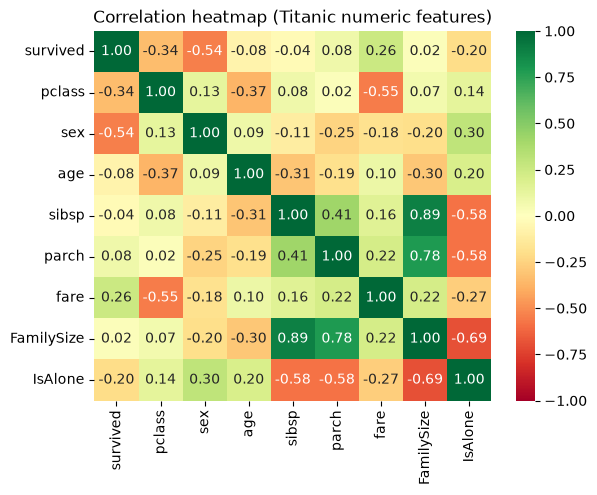

In [ ]:
# Just to see what has hige corr()
import matplotlib.pyplot as plt

num_cols = ['survived', 'pclass', 'sex', 'age', 'sibsp', 'parch', 'fare', 'FamilySize', 'IsAlone']
full_corr = titanic[num_cols].corr()

sns.heatmap(full_corr, annot=True, fmt=".2f", cmap="RdYlGn", vmin=-1, vmax=1)
plt.title("Correlation heatmap (Titanic numeric features)")
plt.show()


### Exercise 5: Univariate feature selection
**Dataset:** Breast Cancer dataset (`sklearn.datasets.load_breast_cancer`)

In [3]:
from sklearn.datasets import load_breast_cancer
from sklearn.feature_selection import SelectKBest, f_classif
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score
# For curiosity
from sklearn.metrics import classification_report, confusion_matrix, roc_auc_score

cancer = load_breast_cancer(as_frame=True)
X = cancer.data
y = cancer.target

# Select top 5 features
choose = SelectKBest(score_func=f_classif, k=5)
x_ = choose.fit_transform(X,y)
#print(x_)
colom_choose = X.columns[choose.get_support()]
print("Coloms: ", list(colom_choose))

# Train/test split
x_train, x_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=50)
# Logistic Regression
model_1 = LogisticRegression(max_iter=100000)
model_1.fit(x_train, y_train)
accuary = accuracy_score(y_test, model_1.predict(x_test))
print(accuary)

x_new_train, x_new_test, y_new_train, y_new_test = train_test_split(X[colom_choose], y, test_size=0.2, random_state=50)

model_2 = LogisticRegression(max_iter=100000)
model_2.fit(x_new_train, y_new_train)
acccuracy2 = accuracy_score(y_new_test, model_2.predict(x_new_test))
print(acccuracy2)
print()
print(confusion_matrix(y_test, model_1.predict(x_test)))
print()
print(confusion_matrix(y_new_test, model_2.predict(x_new_test)))
print()
print(classification_report(y_test, model_1.predict(x_test)))
print()
print(classification_report(y_new_test, model_2.predict(x_new_test)))


Coloms:  ['mean perimeter', 'mean concave points', 'worst radius', 'worst perimeter', 'worst concave points']
0.9736842105263158
0.9385964912280702

[[37  2]
 [ 1 74]]

[[36  3]
 [ 4 71]]

              precision    recall  f1-score   support

           0       0.97      0.95      0.96        39
           1       0.97      0.99      0.98        75

    accuracy                           0.97       114
   macro avg       0.97      0.97      0.97       114
weighted avg       0.97      0.97      0.97       114


              precision    recall  f1-score   support

           0       0.90      0.92      0.91        39
           1       0.96      0.95      0.95        75

    accuracy                           0.94       114
   macro avg       0.93      0.93      0.93       114
weighted avg       0.94      0.94      0.94       114



### Exercise 6: Recursive Feature Elimination (RFE)

In [4]:
from sklearn.feature_selection import RFE

# Use RFE with logistic regression to select top 7 features
model_3 = LogisticRegression(max_iter=100000)
rfe = RFE(estimator=model_3, n_features_to_select=7)
rfe.fit(X,y)

rfe_co = X.columns[rfe.support_]
print("Coloms: ", list(rfe_co))
# Compare accuracy with and without RFE
x_rfe, x_rfe_test, y_rfe, y_rfe_test = train_test_split(X, y, test_size=0.2, random_state=50)
model_4 = LogisticRegression(max_iter=100000)
model_4.fit(x_rfe, y_rfe)
acccuracy3 = accuracy_score(y_rfe_test, model_4.predict(x_rfe_test))
print(acccuracy3)

x_train_rfe, x_test_rfe, y_train_rfe, y_test_rfe = train_test_split(X[rfe_co], y, test_size=0.2, random_state=50)

model_5 = LogisticRegression(max_iter=100000)
model_5.fit(x_train_rfe, y_train_rfe)
acccuracy4 = accuracy_score(y_test_rfe, model_5.predict(x_test_rfe))
print(acccuracy4)
print()
# fore curiosity
rank = pd.Series(rfe.ranking_, index=X.columns).sort_values()
#print(rank)
print()
print(model_4.coef_)
print(model_5.coef_)

common = set(rfe_co) & set(colom_choose)
only_rfe = set(rfe_co) - set(colom_choose)
only_Kbest = set(colom_choose) - set(rfe_co)

print()
print("Common: ", common)
print("Only RFE: ", only_rfe)
print("Only KBest: ", only_Kbest)
print(f"Overlap: {len(common)}/7")


Coloms:  ['mean radius', 'texture error', 'worst radius', 'worst compactness', 'worst concavity', 'worst concave points', 'worst symmetry']
0.9736842105263158
0.9649122807017544


[[ 1.1725165   0.16515577 -0.2795944   0.02260835 -0.15846935 -0.26451274
  -0.53272631 -0.28126453 -0.27288415 -0.03835927 -0.09397854  0.89228403
   0.29309652 -0.07866841 -0.02774791  0.0064258  -0.08942467 -0.04478195
  -0.05692943  0.00268748  0.10672502 -0.38232789 -0.08734516 -0.01631819
  -0.31286748 -0.70937118 -1.28860829 -0.5656825  -0.70805805 -0.10514275]]
[[ 1.29205625 -1.19213254 -2.09275258 -1.70684405 -2.46870645 -0.86922362
  -0.88568245]]

Common:  {'worst concave points', 'worst radius'}
Only RFE:  {'worst symmetry', 'texture error', 'worst compactness', 'worst concavity', 'mean radius'}
Only KBest:  {'mean perimeter', 'worst perimeter', 'mean concave points'}
Overlap: 2/7
